# Training Model Supervised: SmartBearing (CWRU Bearing Fault Detection)
**Kelompok 5 | Peran: ML Engineer 1 (Supervised Learning)**

**Tujuan:** membangun model klasifikasi yang menebak kondisi bearing dari 13 fitur getaran.
Ada **4 kelas**: `Ball` (kerusakan bola), `IR` (inner race), `OR` (outer race), dan `Normal`.

**Alur kerja notebook ini:**
1. Import library dan lokasi proyek
2. Load data hasil preprocessing
3. Pisahkan fitur dan label, lalu cek kualitas data
4. Lihat distribusi kelas
5. Tuning Random Forest
6. Bandingkan dengan algoritma lain
7. Evaluasi di data testing
8. Confusion matrix
9. Feature importance
10. Simpan model
11. Simpan metrik
12. Uji muat ulang model

## Tahap 1: Import Library dan Lokasi Proyek
Sel ini memuat library yang dipakai (pandas, numpy, matplotlib, seaborn, scikit-learn, joblib).

Folder root proyek dicari **otomatis**: notebook naik ke folder induk sampai menemukan folder yang berisi `preprocessing.py` dan `models`. Dengan begitu path ke data dan model tetap benar walaupun notebook dibuka dari folder `training/`.

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Cari folder root project secara otomatis
ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "preprocessing.py").exists()
        and (p / "models").exists()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Root proyek SmartBearing tidak ditemukan."
    )

print("Folder project:", ROOT)

Folder project: c:\Users\Tetah\MachineLearning-Kelompok-5


## Tahap 2: Load Data
Data diambil dari hasil kerja Data Engineer:
- `train_scaled.csv` dan `test_scaled.csv`: data yang sudah dibersihkan, ditambah fitur turunan, di-scale, dan dibagi train/test (80:20).
- `feature_list.json`: daftar dan urutan 13 fitur yang dipakai model.

**Hasil:** data training **1.840 baris**, data testing **460 baris**. Masing-masing 14 kolom (13 fitur + 1 kolom `label`). Nilai fitur sudah di-scale, makanya banyak yang negatif dan kecil.

In [39]:
train = pd.read_csv(
    ROOT / "data/processed/train_scaled.csv"
)

test = pd.read_csv(
    ROOT / "data/processed/test_scaled.csv"
)

# Membaca konfigurasi fitur
with open(
    ROOT / "models/feature_list.json",
    encoding="utf-8"
) as f:
    config = json.load(f)

features = config["features"]

print("Data training:", train.shape)
print("Data testing :", test.shape)
print("Jumlah fitur :", len(features))

display(train.head())

Data training: (1840, 14)
Data testing : (460, 14)
Jumlah fitur : 13


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,peak_to_peak,abs_peak,energy,sd_rms_ratio,label
0,-0.662123,0.641092,0.821969,-0.652073,-0.650340,0.187843,-0.499451,-0.447197,-0.671856,-0.652777,-0.672518,-0.554014,-0.823781,0
1,-0.846710,0.845341,-0.269629,-0.911913,-0.910600,-0.219356,-0.526000,-0.476661,-0.746596,-0.847634,-0.851761,-0.602431,-2.830055,2
2,-0.724752,0.742691,0.984238,-0.709371,-0.706406,-0.448338,-0.588028,-0.699273,-0.709158,-0.735183,-0.733334,-0.567558,-1.536624,0
3,2.178693,-2.135105,-0.133604,2.499247,2.500256,0.842824,0.398899,0.331479,1.622162,2.160860,2.086054,2.954744,0.845307,3
4,-0.568632,0.549548,-1.052603,-0.756940,-0.759304,-0.887399,0.730676,1.674869,-0.479046,-0.560090,-0.581734,-0.578768,0.359595,0


## Tahap 3: Pisahkan Fitur (X) dan Label (y), Cek Kualitas Data
- **X** berisi 13 fitur getaran, **y** berisi label kondisi bearing (angka 0 sampai 3).
- `label_encoder.pkl` dipakai untuk menerjemahkan angka kembali ke nama kelas: `Ball`, `IR`, `Normal`, `OR`.
- Baris `assert` memastikan fiturnya tepat 13 dan tidak ada nilai kosong atau tak hingga. Kalau ada yang salah, sel ini berhenti dengan error.

**Hasil:** kelas `Ball`, `IR`, dan `OR` masing-masing 552 data, sedangkan `Normal` hanya 184 data di data training.

In [40]:
X_train = train[features]
X_test = test[features]

y_train = train["label"].astype(int)
y_test = test["label"].astype(int)

# Load encoder kelas
encoder = joblib.load(
    ROOT / "models/label_encoder.pkl"
)

print("Fitur:", len(features))
print("Label:", list(encoder.classes_))

print("\nDistribusi training:")
print(y_train.value_counts().sort_index())

assert len(features) == 13
assert X_train.notna().all().all()
assert X_test.notna().all().all()
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()

Fitur: 13
Label: ['Ball', 'IR', 'Normal', 'OR']

Distribusi training:
label
0    552
1    552
2    184
3    552
Name: count, dtype: int64


## Tahap 4: Visualisasi Distribusi Kelas
Grafik batang untuk melihat apakah jumlah data tiap kelas seimbang.

**Temuan:** kelas `Normal` jumlahnya sekitar sepertiga kelas lain, jadi datanya tidak sepenuhnya seimbang. Karena itu evaluasi memakai **F1-macro** (rata-rata semua kelas dengan bobot sama), bukan accuracy saja.

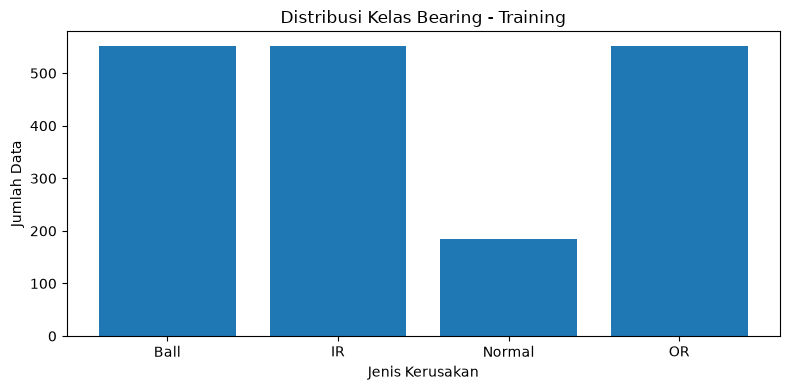

In [41]:
counts = y_train.value_counts().sort_index()

labels = [
    encoder.inverse_transform([int(i)])[0]
    for i in counts.index
]

plt.figure(figsize=(8, 4))
plt.bar(labels, counts.values)
plt.title("Distribusi Kelas Bearing - Training")
plt.xlabel("Jenis Kerusakan")
plt.ylabel("Jumlah Data")
plt.tight_layout()
plt.show()

## Tahap 5: Tuning Hyperparameter Random Forest
**Random Forest** menggabungkan banyak pohon keputusan, lalu hasil akhirnya ditentukan lewat voting.

**Tuning** adalah mencari pengaturan terbaik model. Di sini dipakai `RandomizedSearchCV`:
- Ada 108 kombinasi pengaturan (jumlah pohon, kedalaman, dan seterusnya), tapi hanya **10 kombinasi acak** yang dicoba supaya cepat.
- Tiap kombinasi diuji dengan **3-fold stratified cross-validation** (data latih dipecah 3 bagian, dilatih dan diuji bergantian dengan proporsi kelas dijaga).
- Skor penilaian: **F1-macro**.

**Hasil:** pengaturan terbaik `n_estimators=200`, `max_depth=None`, `min_samples_split=5`, `min_samples_leaf=1`, `class_weight=None`, dengan **F1-macro CV = 0,9741**. Model terbaik disimpan di variabel `model`.

In [42]:
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=10,
    cv=cv,
    scoring="f1_macro",
    random_state=42,
    n_jobs=-1,
    refit=True
)

search.fit(X_train, y_train)

model = search.best_estimator_

print("Best Parameters:")
print(search.best_params_)

print("\nBest CV F1 Macro:")
print(search.best_score_)

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None, 'class_weight': None}

Best CV F1 Macro:
0.9741238045649219


## Tahap 6: Bandingkan dengan Algoritma Lain
Tabel ini adalah **bukti pemilihan algoritma**. Semua model dinilai dengan cross-validation yang sama (3-fold, F1-macro) pada data training saja. Data testing belum dipakai.

| Model | F1-macro CV |
|---|---|
| RandomForest (tuning) | 0,9741 |
| RandomForest (default) | 0,9732 |
| HistGradBoost | 0,9710 |
| KNN | 0,9540 |
| SVM | 0,9029 |
| LogisticRegression | 0,8969 |

**Cara membaca:**
- Random Forest paling tinggi pada data ini, tapi selisihnya dengan HistGradBoost sangat tipis (0,003), jadi keduanya praktis setara.
- Model lain memakai pengaturan standar tanpa tuning, sehingga perbandingannya sedikit menguntungkan Random Forest. Baris *RandomForest (default)* disertakan sebagai pembanding yang adil.
- `NaN` pada kolom `std` baris tuning wajar: skornya diambil dari hasil `search` yang hanya menyimpan satu rata-rata.

In [43]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import pandas as pd

models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, random_state=42),
    "KNN":                KNeighborsClassifier(n_neighbors=5),
    "SVM":                SVC(kernel="rbf", random_state=42),
    "RandomForest (default)": RandomForestClassifier(random_state=42, n_jobs=1),
    "HistGradBoost":      HistGradientBoostingClassifier(random_state=42),
}

rows = []
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    rows.append({"model": name, "cv_f1_macro": s.mean(), "std": s.std()})

# Tambahkan Random Forest hasil tuning (skor dari search di atas)
rows.append({"model": "RandomForest (tuning)", "cv_f1_macro": search.best_score_, "std": float("nan")})

cv_table = pd.DataFrame(rows).sort_values("cv_f1_macro", ascending=False).reset_index(drop=True)
cv_table.round(4)

,model,cv_f1_macro,std
0,RandomForest (tuning),0.9741,NaN
1,RandomForest (default),0.9732,0.0017
2,HistGradBoost,0.9710,0.0045
3,KNN,0.9540,0.0045
4,SVM,0.9029,0.0015
5,LogisticRegression,0.8969,0.0006


## Tahap 7: Evaluasi di Data Testing
Ini pertama kalinya data testing dipakai. Data ini belum pernah dilihat model, jadi hasilnya mewakili kemampuan model pada data baru.

Metrik:
- **Accuracy**: persentase tebakan yang benar.
- **Precision**: dari semua yang diprediksi kelas X, berapa yang benar-benar X.
- **Recall**: dari semua data X yang sebenarnya, berapa yang berhasil terdeteksi.
- **F1-score**: gabungan precision dan recall.

**Hasil:** **Accuracy = 0,9543** dan **F1-macro = 0,9617**. Kelas `IR` dan `Normal` hampir sempurna (recall 1,00). Kelas `Ball` paling sulit (recall 0,90, F1 0,92), disusul `OR` (F1 0,94).

In [44]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("Accuracy:", round(accuracy, 4))
print("F1 Macro:", round(f1_macro, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(encoder.classes_))),
        target_names=encoder.classes_,
        zero_division=0
    )
)

Accuracy: 0.9543
F1 Macro: 0.9617

Classification Report:
              precision    recall  f1-score   support

        Ball       0.95      0.90      0.92       138
          IR       0.98      1.00      0.99       138
      Normal       1.00      1.00      1.00        46
          OR       0.92      0.95      0.94       138

    accuracy                           0.95       460
   macro avg       0.96      0.96      0.96       460
weighted avg       0.95      0.95      0.95       460



## Tahap 8: Confusion Matrix
Tabel yang menunjukkan **kelas asli (baris)** versus **tebakan model (kolom)**. Angka di diagonal adalah tebakan yang benar.

**Temuan:**
- `IR` (138/138) dan `Normal` (46/46) semuanya benar.
- Kesalahan hanya terjadi antara `Ball` dan `OR`: 11 data `Ball` ditebak `OR`, 7 data `OR` ditebak `Ball`, dan 3 data `Ball` ditebak `IR`.
- Artinya pola getaran `Ball` dan `OR` paling mirip bagi model.

Gambar disimpan ke `training/outputs/confusion_matrix.png`.

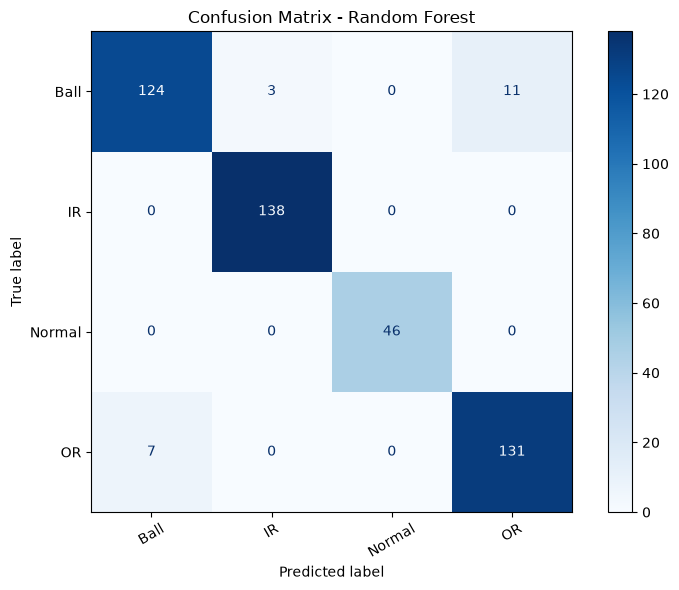

In [45]:
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=list(range(len(encoder.classes_))),
    display_labels=encoder.classes_,
    cmap="Blues",
    ax=ax
)

plt.title("Confusion Matrix - Random Forest")
plt.xticks(rotation=30)
plt.tight_layout()

output_dir = ROOT / "training/outputs"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "confusion_matrix.png",
    dpi=200
)

plt.show()

## Tahap 9: Feature Importance
Menunjukkan fitur mana yang paling berpengaruh pada keputusan Random Forest. Makin panjang batangnya, makin penting fiturnya.

**Temuan:**
- Lima fitur teratas: `abs_peak`, `peak_to_peak`, `min`, `max`, dan `energy`. Semuanya berkaitan dengan **besar atau puncak getaran**.
- Tiga dari lima fitur teratas adalah **fitur turunan** (`abs_peak`, `peak_to_peak`, `energy`), jadi fitur tambahan dari Data Engineer terbukti berguna.
- Fitur paling rendah: `skewness` dan `crest`.
- `sd` dan `rms` berkorelasi hampir sempurna, sehingga nilai pentingnya terbagi di antara keduanya.

Gambar disimpan ke `training/outputs/feature_importance.png`.

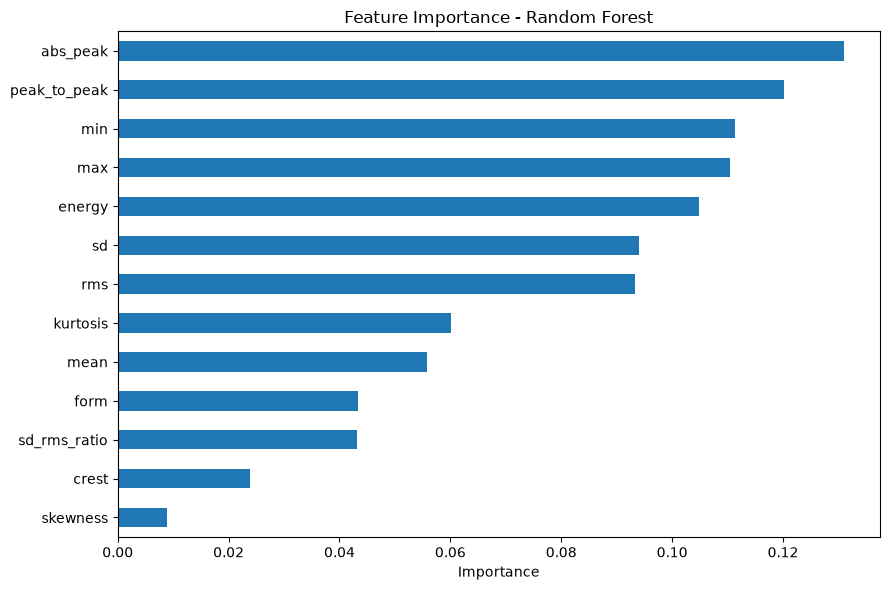

In [46]:
importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values()

plt.figure(figsize=(9, 6))
importance.plot(kind="barh")

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()

plt.savefig(
    output_dir / "feature_importance.png",
    dpi=200
)

plt.show()

## Tahap 10: Simpan Model
Model Random Forest hasil tuning disimpan ke `models/random_forest_pipeline.pkl` dengan `joblib`. File inilah yang dibaca backend (Flask) untuk membuat prediksi.

**Catatan:** walaupun namanya "pipeline", isinya hanya model Random Forest. Scaling dilakukan terpisah memakai `scaler.pkl`, jadi backend harus men-scale input dulu sebelum masuk ke model.

In [47]:
model_path = (
    ROOT / "models/random_forest_pipeline.pkl"
)

joblib.dump(model, model_path)

print("Model berhasil disimpan:")
print(model_path)

Model berhasil disimpan:
c:\Users\Tetah\MachineLearning-Kelompok-5\models\random_forest_pipeline.pkl


## Tahap 11: Simpan Metrik
Hasil evaluasi (accuracy, F1, skor CV, parameter terbaik, daftar fitur, dan kelas) disimpan ke `models/metrics_supervised.json`. File ini bisa dipakai untuk laporan dan untuk menampilkan informasi model di halaman web.

In [48]:
metrics = {
    "algorithm": "Random Forest",
    "accuracy": float(accuracy),
    "f1_macro": float(f1_macro),
    "best_cv_f1_macro": float(search.best_score_),
    "best_parameters": search.best_params_,
    "features": features,
    "classes": list(encoder.classes_)
}

with open(
    ROOT / "models/metrics_supervised.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=4)

print("Metrik berhasil disimpan.")

Metrik berhasil disimpan.


## Tahap 12: Uji Muat Ulang Model
Memastikan file `.pkl` bisa dibuka kembali dan memberi prediksi, seperti yang akan dilakukan backend. Satu sampel dari data testing diprediksi, lalu dibandingkan dengan label aslinya.

**Hasil:** prediksi `OR` sama dengan label aktual `OR`, jadi model tersimpan dengan benar.

In [49]:
loaded_model = joblib.load(model_path)

sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]

result = encoder.inverse_transform(
    [int(prediction)]
)[0]

print("Prediksi:", result)
print(
    "Label aktual:",
    encoder.inverse_transform(
        [int(y_test.iloc[0])]
    )[0]
)

Prediksi: OR
Label aktual: OR


## Kesimpulan
| Item | Hasil |
|---|---|
| Algoritma | Random Forest (hasil tuning dengan RandomizedSearchCV) |
| Parameter terbaik | `n_estimators=200`, `max_depth=None`, `min_samples_split=5`, `min_samples_leaf=1`, `class_weight=None` |
| F1-macro cross-validation | 0,9741 |
| Accuracy data testing | 0,9543 |
| F1-macro data testing | 0,9617 |
| Fitur terpenting | `abs_peak`, `peak_to_peak`, `min`, `max`, `energy` |
| Kesalahan terbanyak | `Ball` tertukar dengan `OR` |
| File keluaran | `random_forest_pipeline.pkl`, `metrics_supervised.json`, `confusion_matrix.png`, `feature_importance.png` |

**Keterbatasan:**
- Kelas `Normal` jauh lebih sedikit daripada kelas lain, sehingga evaluasi memakai F1-macro.
- Data berasal dari satu skenario rekaman (beban dan frekuensi sampling yang sama), jadi hasilnya belum tentu berlaku untuk kondisi mesin lain.
- Perbandingan algoritma memakai pengaturan standar untuk model selain Random Forest.

**Langkah berikutnya:** model diserahkan ke Backend Developer untuk diintegrasikan ke Flask, dengan input mentah diproses lewat scaler dan 13 fitur yang sama.